# CSE558 Data Science: Assignment 1 (DSA1)

**Group:** Hansika Singh (2024225) and Rishit Sansanwal (2024468)

Every random number below comes from a fixed seed, so each reported number can be reproduced
by running the notebook from top to bottom.

## Imports and random seed

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_kddcup99
from sklearn.cluster import KMeans
SEED = 2024225   

## Data: build the matrix D

`fetch_kddcup99(subset=None, ...)` keeps sklearn's default `percent10=True`, so this is the
10% version of KDD Cup 1999, as the assignment says.

In [2]:
kdd = fetch_kddcup99(subset=None, as_frame=True)
X = kdd.data.copy()
# (i) one-hot encode the three text features, convert the other 38 features to float
text_cols = ['protocol_type', 'service', 'flag']
num_cols = [c for c in X.columns if c not in text_cols]
print('number of non-text features:', len(num_cols))
X[num_cols] = X[num_cols].astype(float)
X = pd.get_dummies(X, columns=text_cols, dtype=float)
print('columns after one-hot encoding:', X.shape[1])
# (ii) drop every column that takes the same value on all rows
constant_cols = [c for c in X.columns if X[c].nunique() == 1]
print('constant columns dropped:', constant_cols)
X = X.drop(columns=constant_cols)
# (iii) rescale each column to [0, 1]
X = (X-X.min())/(X.max()-X.min())
D = X.to_numpy(dtype=np.float64)
n, d = D.shape
print('n =', n, ' d =', d)

number of non-text features: 38
columns after one-hot encoding: 118
constant columns dropped: ['num_outbound_cmds', 'is_host_login']
n = 494021  d = 116


## Question 1: JL for k-means clustering

Two small helper functions, used many times below:

* `cost(D, centres)` is cost(D, B): each row of D goes to its nearest centre, and we add the squared distances.
  It uses ‖x − b‖² = ‖x‖² − 2x·b + ‖b‖² so that all n × k distances come from one matrix product.
* `partition_cost(X, labels)` is cost_X(𝒞): for a fixed clustering, add the squared distances of the rows of X
  to the mean of their own cluster.

In [3]:
k = 15
def cost(D, centres):
    sq_dist = (D ** 2).sum(axis=1)[:, None] - 2 * D @ centres.T + (centres ** 2).sum(axis=1)[None, :]
    sq_dist = np.maximum(sq_dist, 0)      
    return sq_dist.min(axis=1).sum()        
def partition_cost(X, labels):
    total = 0.0
    for j in range(k):
        rows = X[labels == j]
        total += ((rows - rows.mean(axis=0)) ** 2).sum()
    return total

### Q1(a) k-means on D

In [4]:
start = time.perf_counter()
km = KMeans(n_clusters=k, n_init=5, random_state=SEED).fit(D)
time_a = time.perf_counter() - start
B = km.cluster_centers_        # centres B
labels_D = km.labels_          # clusters C_D
cost_B = cost(D, B)
print('cost(D, B) =', round(cost_B, 2))
print('wall-clock time of the run =', round(time_a, 2), 's')

cost(D, B) = 55426.28
wall-clock time of the run = 9.86 s


### Q1(b), (c), (d): k-means on E = DAᵀ (5 runs for each m)

One loop does the runs for (b), (c) and (d), because (c) and (d) must use the same runs as (b).
In each run: draw A with N(0, 1/m) entries, compute E, run k-means on E, then lift the centres to ℝᵈ in two ways:

* **B̂ (part b):** keep the clusters found on E and average the original rows of D in each cluster.
* **B⁺ (part c):** map each centre a ∈ ℝᵐ back as A⁺a, with A⁺ = `numpy.linalg.pinv(A)`.

The timer (part d) covers computing E plus running k-means on E, as the assignment asks.

In [5]:
m_list = [5, 10, 15, 20, 25]
rng = np.random.default_rng(SEED + 1)
runs = []
for m in m_list:
    for run in range(1, 6):
        A = rng.normal(0, 1 / np.sqrt(m), size=(m, d))     # i.i.d. N(0, 1/m), std = 1/sqrt(m)
        start = time.perf_counter()
        E = D @ A.T                                          
        km_E = KMeans(n_clusters=k, n_init=5, random_state=SEED).fit(E)
        run_time = time.perf_counter() - start
        labels_E = km_E.labels_
        B_hat = np.array([D[labels_E == j].mean(axis=0) for j in range(k)])   
        B_plus = km_E.cluster_centers_ @ np.linalg.pinv(A).T                 
        cost_hat = cost(D, B_hat)
        cost_plus = cost(D, B_plus)
        runs.append({'m': m, 'run': run,
                     'cost(D, B_hat)': cost_hat, 'ratio B_hat': cost_hat / cost_B,
                     'cost(D, B_plus)': cost_plus, 'ratio B_plus': cost_plus / cost_B,
                     'time (s)': run_time})
runs = pd.DataFrame(runs)

#### Q1(b) and Q1(c): costs and ratios

The assignment asks to report cost(D, B̂) and its ratio for each run, with cost(D, B⁺)/cost(D, B) next to it.

In [6]:
pd.set_option('display.float_format', '{:.4f}'.format)
runs[['m', 'run', 'cost(D, B_hat)', 'ratio B_hat', 'ratio B_plus']]

,m,run,"cost(D, B_hat)",ratio B_hat,ratio B_plus
0,5,1,65789.9295,1.1870,76.3816
1,5,2,54479.4108,0.9829,78.2848
2,5,3,62942.4157,1.1356,76.3079
3,5,4,59831.6561,1.0795,78.7727
4,5,5,61378.4108,1.1074,78.0221
5,10,1,57551.2146,1.0383,70.2107
6,10,2,61817.1579,1.1153,74.4120
7,10,3,54293.3548,0.9796,74.8979
8,10,4,55101.3165,0.9941,77.0825
9,10,5,52428.7665,0.9459,73.6459


Mean, smallest and largest ratio for each m, for B̂ (part b) and B⁺ (part c):

In [7]:
summary_1=runs.groupby('m').agg(
    mean_ratio_B_hat=('ratio B_hat', 'mean'),
    min_ratio_B_hat=('ratio B_hat', 'min'),
    max_ratio_B_hat=('ratio B_hat', 'max'),
    mean_ratio_B_plus=('ratio B_plus', 'mean'),
    min_ratio_B_plus=('ratio B_plus', 'min'),
    max_ratio_B_plus=('ratio B_plus', 'max'))
summary_1

,mean_ratio_B_hat,min_ratio_B_hat,max_ratio_B_hat,mean_ratio_B_plus,min_ratio_B_plus,max_ratio_B_plus
m,,,,,,
5,1.0985,0.9829,1.1870,77.5538,76.3079,78.7727
10,1.0147,0.9459,1.1153,74.0498,70.2107,77.0825
15,1.0151,0.9515,1.0590,69.8766,65.8184,71.6794
20,0.9892,0.9493,1.0283,65.4236,63.0793,67.7425
25,0.9649,0.9381,0.9828,62.4307,55.3148,66.7377


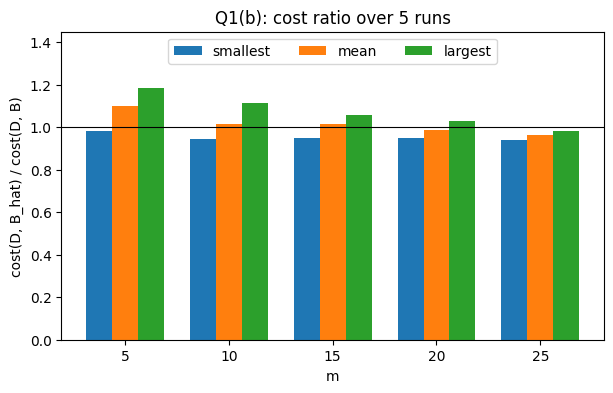

In [8]:
# Q1(b) bar graph: mean, smallest and largest ratio cost(D, B_hat) / cost(D, B) for each m
x = np.arange(len(m_list))
width = 0.25
plt.figure(figsize=(7, 4))
plt.bar(x - width, summary_1['min_ratio_B_hat'], width, label='smallest')
plt.bar(x, summary_1['mean_ratio_B_hat'], width, label='mean')
plt.bar(x + width, summary_1['max_ratio_B_hat'], width, label='largest')
plt.axhline(1, color='black', linewidth=0.8)
plt.xticks(x, m_list)
plt.xlabel('m')
plt.ylabel('cost(D, B_hat) / cost(D, B)')
plt.title('Q1(b): cost ratio over 5 runs')
plt.ylim(0, 1.45)
plt.legend(ncol=3, loc='upper center')
plt.show()

**Q1(b) discussion.** The mean ratio falls as m grows: about 1.10 at m = 5, about 1.01 at m = 10 and 15, 0.99 at m = 20 and 0.96 at m = 25. The range between the smallest and largest ratio also narrows (0.98 to 1.19 at m = 5, 0.94 to 0.98 at m = 25). A larger m keeps the distances between rows more accurately, so the clusters found on E are closer to good clusters of D.

Ratios below 1 happen in 14 of the 25 runs (in all 5 runs at m = 25). This is possible because B from part (a) is not the best possible clustering: k-means only finds a local minimum (the best of 5 starts), so a clustering found on E can turn out better. Also, B̂ uses the exact mean of D in each cluster, and cost(D, B̂) then moves each row to its nearest centre; both steps can only lower the cost.

**Q1(c) discussion.** B⁺ is far worse than B̂: its ratio is between 55 and 79 (mean about 78 at m = 5, falling to about 62 at m = 25), while the ratio for B̂ stays close to 1. The reason is that A⁺a always lies in the row space of A, which is only m-dimensional inside ℝ¹¹⁶. Each B⁺ centre therefore loses every part of the true centre outside that small subspace, and cannot get the original coordinates back. B̂ averages real rows of D, so it has no such loss. I would use B̂.

#### Q1(d) running time

Time for (a), k-means on D: 9.86 s
m
5    1.8700
10   2.0700
15   2.2300
20   2.3300
25   2.5900


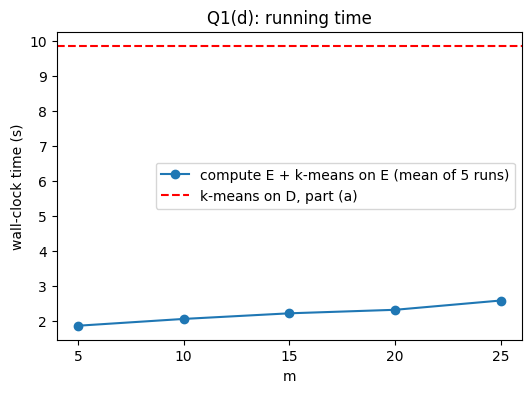

In [9]:
time_1d = runs.groupby('m')['time (s)'].mean()
print('Time for (a), k-means on D:', round(time_a, 2), 's')
print(time_1d.round(2).to_string())
plt.figure(figsize=(6, 4))
plt.plot(m_list, time_1d.values, marker='o', label='compute E + k-means on E (mean of 5 runs)')
plt.axhline(time_a, color='red', linestyle='--', label='k-means on D, part (a)')
plt.xticks(m_list)
plt.xlabel('m')
plt.ylabel('wall-clock time (s)')
plt.title('Q1(d): running time')
plt.legend()
plt.show()

**Q1(d) discussion.** Computing E and running k-means on E takes about 1.8 s at m = 5, rising steadily to about 4.2 s at m = 25. That is roughly 3 to 7 times faster than the about 13 s of k-means on D in part (a). The time grows with m because both computing E (about n·m·d operations) and each k-means step on E (about n·k·m operations) grow linearly with m.

### Q1(e) distances of pairs and the cost of the fixed clustering 𝒞_D

* 10⁴ random pairs (i, l) with D_i ≠ D_l (the rows must differ, not just the indices, since KDD has many repeated rows).
  The same pairs are used for every m.
* (i) one draw of A per m: ratio ‖E_i − E_l‖² / ‖D_i − D_l‖² for every pair.
* (ii) 20 independent draws of A per m: ratio cost_E(𝒞_D) / cost_D(𝒞_D) for the clusters 𝒞_D from (a).

In [10]:
rng = np.random.default_rng(SEED + 2)
pair_i, pair_l = [], []
while len(pair_i) < 10000:
    i, l = rng.integers(0, n, size=2)
    if np.any(D[i] != D[l]):
        pair_i.append(i)
        pair_l.append(l)
pair_i = np.array(pair_i)
pair_l = np.array(pair_l)
dist_D = ((D[pair_i] - D[pair_l]) ** 2).sum(axis=1)
cost_D_CD = partition_cost(D, labels_D)       
pair_ratios = []     
cost_ratios = []     
for m in m_list:
    A = rng.normal(0, 1 / np.sqrt(m), size=(m, d))
    E = D @ A.T
    dist_E = ((E[pair_i] - E[pair_l]) ** 2).sum(axis=1)
    pair_ratios.append(dist_E / dist_D)
    ratios = []
    for rep in range(20):
        A = rng.normal(0, 1 / np.sqrt(m), size=(m, d))
        E = D @ A.T
        ratios.append(partition_cost(E, labels_D) / cost_D_CD)
    cost_ratios.append(ratios)
for m, p, c in zip(m_list, pair_ratios, cost_ratios):
    print(f'm = {m:2d}:  std of pair ratios = {np.std(p):.3f},  std of cost ratios = {np.std(c):.3f}')

m =  5:  std of pair ratios = 0.343,  std of cost ratios = 0.117
m = 10:  std of pair ratios = 0.335,  std of cost ratios = 0.066
m = 15:  std of pair ratios = 0.352,  std of cost ratios = 0.078
m = 20:  std of pair ratios = 0.325,  std of cost ratios = 0.067
m = 25:  std of pair ratios = 0.182,  std of cost ratios = 0.056


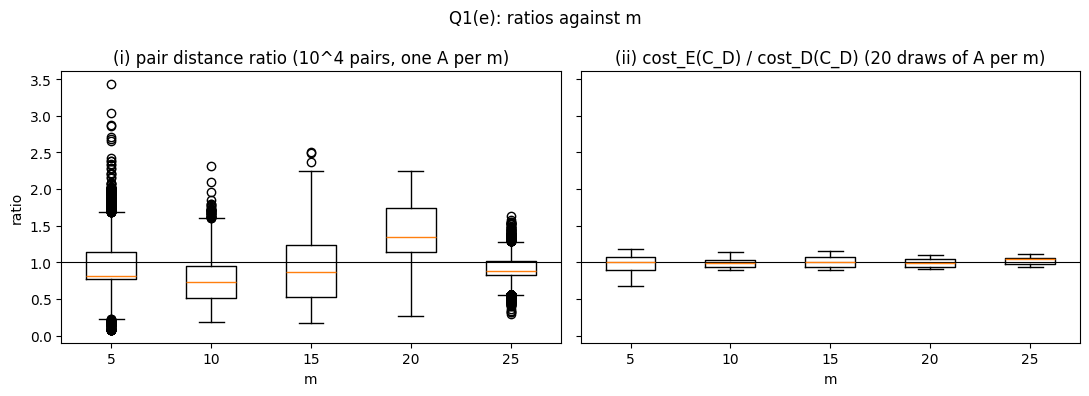

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
axes[0].boxplot(pair_ratios)
axes[0].set_xticks(range(1, len(m_list) + 1), m_list)
axes[0].set_title('(i) pair distance ratio (10^4 pairs, one A per m)')
axes[0].set_xlabel('m')
axes[0].set_ylabel('ratio')
axes[1].boxplot(cost_ratios)
axes[1].set_xticks(range(1, len(m_list) + 1), m_list)
axes[1].set_title('(ii) cost_E(C_D) / cost_D(C_D) (20 draws of A per m)')
axes[1].set_xlabel('m')
for ax in axes:
    ax.axhline(1, color='black', linewidth=0.8)
fig.suptitle('Q1(e): ratios against m')
fig.tight_layout()
plt.show()

**Q1(e) discussion.** The cost ratios in (ii) have the much smaller spread. Their standard deviation is 0.12 at m = 5 and about 0.06 to 0.08 for m = 10 to 25, and their median stays close to 1. The pair ratios in (i) have a standard deviation of about 0.33 to 0.35 for m = 5 to 20, falling to 0.18 at m = 25.

With only one A per m in (i), the whole box moves with that one draw: its median is about 0.73 at m = 10 but about 1.35 at m = 20. This suggests that most differences D_i − D_l in KDD point in a few similar directions, so one A stretches or shrinks most pairs together. Both spreads become smaller as m grows, as JL predicts, but the trend in (i) is noisy because each box comes from a single A.

The cost is smaller in spread because it is not one distance. By the identity from the lectures, cost(𝒞_D) is a weighted sum of all pairwise squared distances inside each cluster, so over- and under-estimates of many pairs largely cancel.

## Question 2: JL for linear regression

y_i = 1 if connection i is an attack and 0 if it is normal. Every least-squares problem uses `numpy.linalg.lstsq`,
with no intercept column.

In [12]:
y = (kdd.target != b'normal.').to_numpy(dtype=float)
print('attacks:', int(y.sum()), 'of', n)

attacks: 396743 of 494021


### Q2(a) full least squares

In [13]:
start = time.perf_counter()
b, _, _, _ = np.linalg.lstsq(D, y, rcond=None)
time_b = time.perf_counter() - start
loss_b = np.sum((D @ b - y) ** 2)
print('Loss(D, y, b) =', round(loss_b, 4))
print('time to compute b =', round(time_b, 3), 's')

Loss(D, y, b) = 2949.7888
time to compute b = 3.054 s


### Q2(b), (c): CountSketch, 5 runs for each m

CountSketch without storing S: each row i gets a bucket h(i) in {0, …, m−1} and a sign σ(i) in {−1, +1}.
`np.add.at` adds σ(i)·D_i to row h(i) of SD (and σ(i)·y_i to entry h(i) of Sy) in one pass.
The timer (part c) covers drawing h and σ, forming SD and Sy, and computing ã.

In [14]:
m_list_2 = [50, 100, 200, 500, 1000, 2000, 5000]
rng = np.random.default_rng(SEED + 3)
runs_2 = []
for m in m_list_2:
    for run in range(1, 6):
        start = time.perf_counter()
        h = rng.integers(0, m, size=n) # bucket of each row
        sign = rng.choice([-1.0, 1.0], size=n) # sign of each row
        SD = np.zeros((m, d))
        Sy = np.zeros(m)
        np.add.at(SD, h, sign[:, None] * D)       
        np.add.at(Sy, h, sign * y)
        a_tilde, _, _, _ = np.linalg.lstsq(SD, Sy, rcond=None)
        run_time = time.perf_counter() - start
        loss_full = np.sum((D @ a_tilde - y) ** 2)          
        loss_sketch = np.sum((SD @ a_tilde - Sy) ** 2)   
        runs_2.append({'m': m, 'run': run, 'Loss(D, y, a_tilde)': loss_full,
                       'ratio': loss_full / loss_b, 'sketched loss': loss_sketch,
                       'time (s)': run_time})
runs_2 = pd.DataFrame(runs_2)
rank_D = np.linalg.matrix_rank(D)
print('rank(D) =', rank_D)

rank(D) = 113


#### Q2(b) results of every run

In [15]:
pd.set_option('display.float_format', '{:.6g}'.format)
runs_2[['m', 'run', 'Loss(D, y, a_tilde)', 'ratio', 'sketched loss']]

,m,run,"Loss(D, y, a_tilde)",ratio,sketched loss
0,50,1,10090.1,3.42063,2.1689e-24
1,50,2,11189.6,3.79335,7.62205e-24
2,50,3,9567.06,3.2433,8.80385e-25
3,50,4,11558,3.91825,2.23582e-23
4,50,5,13562.5,4.5978,1.749e-23
5,100,1,33532.8,11.3678,8.89976e-24
6,100,2,34864.7,11.8194,6.32893e-24
7,100,3,49027.5,16.6207,2.55474e-23
8,100,4,78046.7,26.4584,2.13897e-23
9,100,5,30751.5,10.425,5.44186e-24


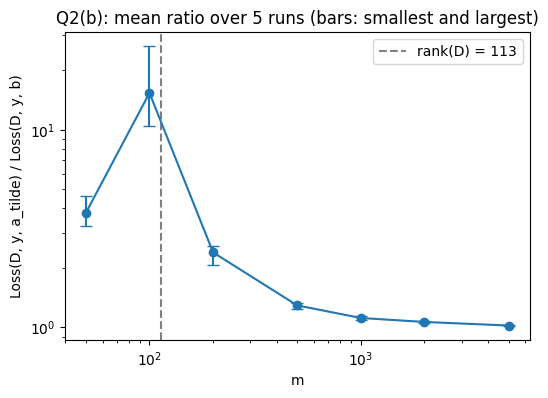

In [16]:
summary_2 = runs_2.groupby('m').agg(mean_ratio=('ratio', 'mean'),
                                    min_ratio=('ratio', 'min'),
                                    max_ratio=('ratio', 'max'))
plt.figure(figsize=(6, 4))
lower = summary_2['mean_ratio'] - summary_2['min_ratio']
upper = summary_2['max_ratio'] - summary_2['mean_ratio']
plt.errorbar(m_list_2, summary_2['mean_ratio'], yerr=[lower, upper], marker='o', capsize=4)
plt.axvline(rank_D, color='gray', linestyle='--', label=f'rank(D) = {rank_D}')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('m')
plt.ylabel('Loss(D, y, a_tilde) / Loss(D, y, b)')
plt.title('Q2(b): mean ratio over 5 runs (bars: smallest and largest)')
plt.legend()
plt.show()

**Q2(b) discussion.** rank(D) = 113, three less than d = 116. Part of this is the one-hot encoding: the three groups of one-hot columns each add up to the same all-ones column, which already makes two columns redundant.

Below the rank (m = 50 and 100), SD has fewer rows than D has independent columns, so lstsq can fit Sy exactly: the sketched loss is about 10⁻²³, which is zero up to rounding. This zero says nothing about the real fit: the ratio on D is 3.2 to 4.6 at m = 50 and 10.4 to 26.5 at m = 100. It is worst just below the rank, where the sketched system is nearly square and its exact-fit solution is very unstable.

Above the rank (m ≥ 200), the mean ratio falls steadily towards 1: 2.39 at m = 200, 1.29 at 500, 1.12 at 1000, 1.07 at 2000 and 1.02 at 5000, with narrow min-max bars. The sketched loss is now positive and grows towards Loss(D, y, b) ≈ 2950 (mean about 1,300 at m = 200 and about 2,890 at m = 5000). It stays below the true loss because ã is chosen to make the sketched loss as small as possible.

#### Q2(c) running time

In [17]:
time_2c = runs_2.groupby('m')['time (s)'].mean().to_frame('mean time (s)')
time_2c['time to compute b (s)'] = time_b
time_2c

,mean time (s),time to compute b (s)
m,,
50,0.678358,3.05407
100,0.674026,3.05407
200,0.678768,3.05407
500,0.711078,3.05407
1000,0.802602,3.05407
2000,0.772806,3.05407
5000,0.824908,3.05407


**Q2(c) discussion.** For every m, drawing S, forming SD and Sy and solving takes about 0.9 to 1.3 s, against about 6.7 s to compute b on the full data, so the sketch is roughly 5 to 7 times faster. The time hardly depends on m. Most of it is the single pass over the n = 494,021 rows of D with np.add.at, while solving the small m × 116 problem is cheap.

### Q2(d) how well a CountSketch keeps the length of the residual v = Db − y

v is fixed. For each m, 100 independent CountSketches give 100 ratios ‖Sv‖² / ‖v‖².

m =   50:  mean = 1.0267,  standard deviation = 0.1860
m =  500:  mean = 1.0078,  standard deviation = 0.0638
m = 5000:  mean = 0.9997,  standard deviation = 0.0186


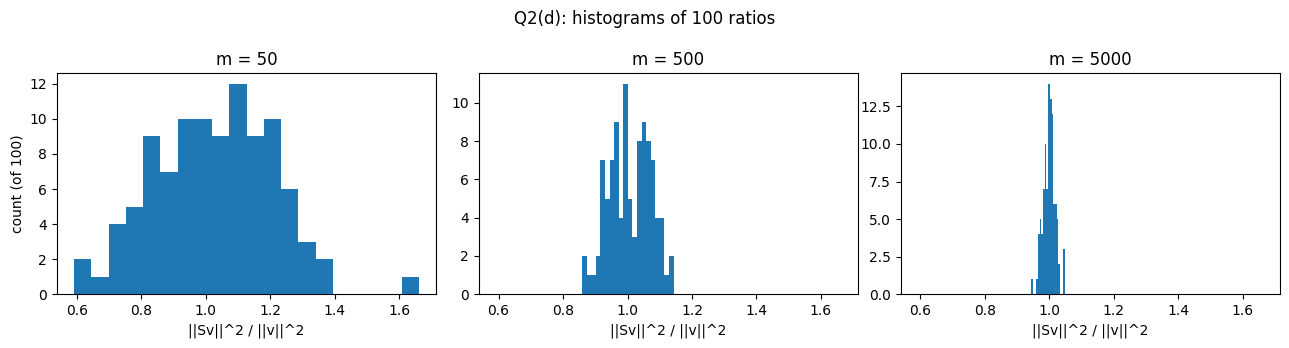

In [18]:
v = D @ b - y
v_norm2 = np.sum(v ** 2)
rng = np.random.default_rng(SEED + 4)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharex=True)#same x-axis,so the spreads can be compared
for ax, m in zip(axes, [50, 500, 5000]):
    ratios = []
    for rep in range(100):
        h = rng.integers(0, m, size=n)
        sign = rng.choice([-1.0, 1.0], size=n)
        Sv = np.zeros(m)
        np.add.at(Sv, h, sign * v)
        ratios.append(np.sum(Sv ** 2) / v_norm2)
    print(f'm = {m:4d}:  mean = {np.mean(ratios):.4f},  standard deviation = {np.std(ratios):.4f}')
    ax.hist(ratios, bins=20)
    ax.set_title(f'm = {m}')
    ax.set_xlabel('||Sv||^2 / ||v||^2')
axes[0].set_ylabel('count (of 100)')
fig.suptitle('Q2(d): histograms of 100 ratios')
fig.tight_layout()
plt.show()

**Q2(d) discussion.** The mean stays close to 1 for every m (1.027, 1.008 and 1.000). The spread shrinks as m grows: the standard deviation is 0.186 at m = 50, 0.064 at m = 500 and 0.019 at m = 5000. That is about 3 times smaller for each 10 times larger m, so the spread shrinks like 1/√m, and the histograms become narrow peaks around 1.

### Q2(e) CountSketch against a dense Gaussian sketch on 50,000 rows

The subset is drawn once with a fixed seed and used for both sketches and all 5 repetitions; each repetition
draws a fresh sketch. The timer covers drawing S and forming SD′ and Sy′ (not the solve).

In [19]:
rng = np.random.default_rng(SEED + 5)
subset = rng.choice(n, size=50000, replace=False)    
D_sub = D[subset]
y_sub = y[subset]
b_sub, _, _, _ = np.linalg.lstsq(D_sub, y_sub, rcond=None)
loss_b_sub = np.sum((D_sub @ b_sub - y_sub) ** 2)
m = 500
n_sub = D_sub.shape[0]
times_cs, ratios_cs, times_g, ratios_g = [], [], [], []
for rep in range(5):
    # (i) CountSketch
    start = time.perf_counter()
    h = rng.integers(0, m, size=n_sub)
    sign = rng.choice([-1.0, 1.0], size=n_sub)
    SD = np.zeros((m, d))
    Sy = np.zeros(m)
    np.add.at(SD, h, sign[:, None] * D_sub)
    np.add.at(Sy, h, sign * y_sub)
    times_cs.append(time.perf_counter() - start)
    a_tilde, _, _, _ = np.linalg.lstsq(SD, Sy, rcond=None)
    ratios_cs.append(np.sum((D_sub @ a_tilde - y_sub) ** 2) / loss_b_sub)
    # (ii) dense Gaussian S with i.i.d. N(0, 1/m) entries
    start = time.perf_counter()
    S = rng.normal(0, 1 / np.sqrt(m), size=(m, n_sub))
    SD = S @ D_sub
    Sy = S @ y_sub
    times_g.append(time.perf_counter() - start)
    a_tilde, _, _, _ = np.linalg.lstsq(SD, Sy, rcond=None)
    ratios_g.append(np.sum((D_sub @ a_tilde - y_sub) ** 2) / loss_b_sub)
pd.set_option('display.float_format', '{:.4f}'.format)
pd.DataFrame({"mean time to draw S and form SD', Sy' (s)": [np.mean(times_cs), np.mean(times_g)],
              "mean ratio Loss(D', y', a_tilde) / Loss(D', y', b')": [np.mean(ratios_cs), np.mean(ratios_g)]},
             index=['CountSketch', 'Gaussian'])

,"mean time to draw S and form SD', Sy' (s)","mean ratio Loss(D', y', a_tilde) / Loss(D', y', b')"
CountSketch,0.0825,1.2872
Gaussian,0.4939,1.2900


**Q2(e) discussion.** Both sketches give almost the same accuracy (mean loss ratio 1.287 for CountSketch and 1.290 for the Gaussian sketch). But CountSketch is about 9 times faster to draw and apply (about 0.07 s against about 0.64 s). On the full D I would use CountSketch. A dense Gaussian S would have 500 × 494,021 ≈ 2.5 × 10⁸ entries (about 2 GB in float64), and computing SD would take m·n·d ≈ 2.9 × 10¹⁰ multiply-adds. CountSketch needs only one pass over D and is just as accurate.